Math explanation 

Pitch width = 68m, on 0-100 unit scale -> 1 unit = .68m 
Goal width = 7.32m -> 10.76 units. 

50 units is the center and 10.76/2 = 5.38
So half to the left and right -> 44.6 and 55.4

In [16]:
import os
from pathlib import Path
from dotenv import load_dotenv

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 
load_dotenv(override=True);

In [18]:
data_repo_env = os.getenv("DATA_REPO_PATH")
DATA_REPO_DIR = Path(data_repo_env)

shotscsv = DATA_REPO_DIR / "GW2" / "shots.csv"
playerscsv = DATA_REPO_DIR / "GW2" / "players.csv"

shots = pd.read_csv(shotscsv)
players = pd.read_csv(playerscsv)


In [ ]:
# shots = pd.read_csv("FPL-Core-Insights/data/2025-2026/By Tournament/Premier League/GW2/shots.csv")
# players = pd.read_csv("FPL-Core-Insights/data/2025-2026/By Tournament/Premier League/GW1/players.csv")

In [19]:
left_post = 55.4
right_post = 44.6
crossbar_height = 100/3

In [20]:
shots["goal_mouth_y_rel"] = ((left_post - shots["goal_mouth_y"])/(left_post - right_post)) * 100
shots["goal_mouth_z_rel"] = (shots["goal_mouth_z"] / 100) * crossbar_height

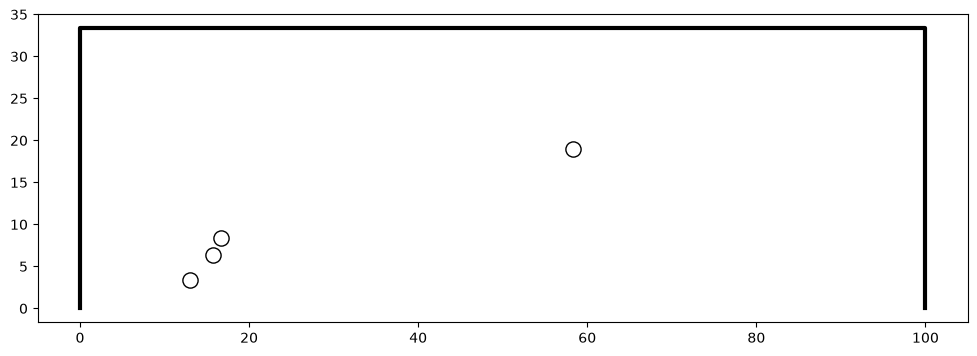

In [22]:
fig, ax = plt.subplots(figsize = (12, 4))

x_coords = [0, 0, 100, 100]
y_coords = [0, crossbar_height, crossbar_height, 0]

# 1. Draw Goal Frame (white line for dark background)
ax.plot(x_coords, y_coords, color="black", lw=3)

shots_player = shots[shots["player_id"] == 154]

ax.scatter( 
    shots_player["goal_mouth_y_rel"],
    shots_player["goal_mouth_z_rel"],
    color="white",
    edgecolors="black",
    s=120
)

plt.show()